<a href="https://colab.research.google.com/github/nhuvtq87/SpartanAssist/blob/main/SpartanAssist_AutoMates_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛡️ SpartanAssist — Multi-Agent AI IT Help Desk
### Team **Auto-Mates**

| Member | Role |
|---|---|
| Sri Sudula | Project Manager / Coordinator |
| Nhu Vo | Tech Lead |
| Liz Pham | Testing Lead |
| Kimberly Gomez | Business Lead |
| Yuvraj Singh | Presentation Lead |
| Jorge Perez | QA Lead |

**What this notebook does:** a LangGraph multi-agent system that triages campus IT requests, answers them from a RAG knowledge base, runs safe automations through an MCP tool server, and hands off to a human when it should.

```
 student ─▶ Privacy Guard ─▶ Intake Agent ──(off-topic)──────────────────────────┐
            (redact PII)     (category, P1-P4,                                   │
                              action, confidence)                                │
                                   │                                             │
                                   ▼                                             │
                             Knowledge Agent ──(P1 / security / not grounded)─┐  │
                             (RAG + citations)                                │  │
                                   │ needs an action        no action         │  │
                                   ▼                           │              ▼  │
                             Workflow Agent ──(failed/repair)──┼──────▶ Escalation Agent
                             (MCP tool server + ticket)        │        (handoff note, team, SLA)
                                   │                           │              │  │
                                   └──────────────▶ Responder ◀┴──────────────┘◀─┘ ─▶ student
```

**What's new vs. the sample notebook**
- **Conditional routing** instead of one straight line, so easy tickets skip escalation and urgent ones skip the queue. The sample sent 4/4 demos to a human.
- **Similarity threshold + citations** on RAG. Weak matches go to a human instead of a guessed answer, and every answer names its KB source.
- **Privacy guard** strips PII *before* any text reaches the LLM or the logs.
- **Real MCP server** (`helpdesk_mcp_server.py`, built on the official `mcp` SDK). The notebook *and* VS Code Copilot both connect to it.
- **20-scenario labeled test set** that scores accuracy against expected answers, not just the model's self-reported confidence.
- **Three run modes:** `gemini` (default when `GOOGLE_API_KEY` is set), `openai`, or `offline` (no key needed: TF-IDF embeddings + rule-based agents, so the demo never dies on a rate limit).

> ⚠️ The knowledge base is a **simulated** campus IT wiki modeled on typical university services. It is not official SJSU IT guidance.

## 📦 1 · Install dependencies

In [ ]:
%pip install -q "langgraph>=0.2" langchain-core langchain-google-genai langchain-openai "chromadb>=0.5" scikit-learn "mcp>=1.9,<2" pandas matplotlib
print("✅ Dependencies ready")

Note: you may need to restart the kernel to use updated packages.
✅ Dependencies ready


## 🔑 2 · Configuration & run mode

In [ ]:
import os, re, json, time, uuid, sqlite3, hashlib, random, textwrap
from datetime import datetime, timedelta
from typing import TypedDict, List, Optional, Literal
import numpy as np, pandas as pd

# Colab: add GOOGLE_API_KEY (or OPENAI_API_KEY) in the 🔑 Secrets panel.
def _secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

GOOGLE_API_KEY = _secret("GOOGLE_API_KEY")
OPENAI_API_KEY = _secret("OPENAI_API_KEY")

# "auto" picks gemini → openai → offline based on which key exists
RUN_MODE = os.environ.get("HELPDESK_MODE", "auto")
if RUN_MODE == "auto":
    RUN_MODE = "gemini" if GOOGLE_API_KEY else ("openai" if OPENAI_API_KEY else "offline")

CONFIG = {
    "gemini":  {"llm": "gemini-2.5-flash", "embed": "models/gemini-embedding-001", "min_sim": 0.55},
    "openai":  {"llm": "gpt-4o-mini",      "embed": "text-embedding-3-small",      "min_sim": 0.35},
    "offline": {"llm": "rule-based",       "embed": "tfidf-local",                 "min_sim": 0.10},
}[RUN_MODE]

TOP_K = 2                    # chunks passed to the answer step
CONFIDENCE_FLOOR = 0.55      # below this, Intake's label isn't trusted → human
WORKDIR = os.path.abspath("spartanassist_runtime"); os.makedirs(WORKDIR, exist_ok=True)
TICKET_DB = os.path.join(WORKDIR, "tickets.db")
random.seed(119); np.random.seed(119)

print(f"🧭 Run mode:   {RUN_MODE}")
print(f"🤖 LLM:        {CONFIG['llm']}")
print(f"📐 Embeddings: {CONFIG['embed']}  (min similarity {CONFIG['min_sim']})")
print(f"🗂️  Runtime dir: {WORKDIR}")

🧭 Run mode:   offline
🤖 LLM:        rule-based
📐 Embeddings: tfidf-local  (min similarity 0.1)
🗂️  Runtime dir: /home/claude/automates/spartanassist_runtime


## 📚 3 · Knowledge base (RAG source documents)
Eleven runbook-style articles. Each `##` section becomes its own chunk, so retrieval returns the *specific* procedure (e.g. "Account lockout") instead of the whole article. That keeps prompts short and answers precise.

In [ ]:
KB = [
 {"id":"KB-NET-01","category":"network","title":"Campus Wi-Fi (eduroam) Troubleshooting","body":"""
## Connect to eduroam
Choose the network named eduroam (not the guest network). Username is your full campus email; password is your campus account password. Accept the campus security certificate when prompted.
## Wi-Fi keeps disconnecting or drops every few minutes
1. Forget eduroam and reconnect. 2. Turn off private / randomized MAC address for eduroam. 3. Disable adapter power saving (Windows: Device Manager > Network adapters > Power Management). 4. Update the wireless driver. 5. Move closer to an access point; dead zones are listed on the outage board. If it still drops on two different devices, report the building and room so Networking can check the access point.
## Connected but no internet
Run the automated network diagnostic. Flush DNS (ipconfig /flushdns on Windows, sudo dscacheutil -flushcache on macOS) and set IP to automatic (DHCP). Check the campus status page for outages.
"""},
 {"id":"KB-NET-02","category":"network","title":"VPN (GlobalProtect) Setup and Errors","body":"""
## Install and connect to the VPN
Download GlobalProtect from the software portal. Portal address: vpn.campus.example. Sign in with your campus account and approve the Duo push. The VPN is needed for library databases, remote desktops and some department drives when off campus.
## VPN will not connect or keeps dropping
1. Confirm your internet works without VPN. 2. Quit and reopen GlobalProtect, then reconnect. 3. If you see 'gateway not responding', pick a different gateway from the menu. 4. Turn off other VPNs and ad blockers. 5. If Duo never arrives, see the MFA article.
"""},
 {"id":"KB-ACC-01","category":"authentication","title":"Password Reset and Account Lockout","body":"""
## Forgot password / reset password
Use the self-service reset portal: verify with your registered recovery email or phone, then choose a new password (minimum 12 characters, not one of your last 5). The reset link expires in 30 minutes. The help desk assistant can send the reset link for you.
## Account locked after failed attempts
Accounts lock for 15 minutes after 5 failed sign-ins. The assistant can unlock the account immediately after identity verification. Repeated lockouts usually mean an old password saved on a phone or laptop; update saved passwords in mail apps and Wi-Fi.
## Account disabled
A disabled account (not locked) is an administrative hold, for example enrollment, HR status or a security block. It cannot be fixed by self-service; it must be reviewed by the Accounts team.
"""},
 {"id":"KB-ACC-02","category":"authentication","title":"Multi-Factor Authentication (Duo)","body":"""
## Not receiving Duo push
Check that the phone has internet, open the Duo app and pull to refresh, and confirm the phone time is set automatically. Use a passcode from the Duo app instead of a push if needed.
## New phone or lost phone
Use a backup device or a one-time bypass code. Lost phones should be removed from your devices list right away. Enrolling a new phone requires identity verification by the help desk.
"""},
 {"id":"KB-SW-01","category":"software","title":"Software Licensing and Installation","body":"""
## Microsoft 365 / Office installation failed
1. Sign in at the Office portal with your campus email and choose Install apps. 2. Uninstall older Office versions first (use the Microsoft Support and Recovery Assistant). 3. Make sure you have 10 GB free and restart. 4. Each student can install on 5 devices; remove an old device if you hit the limit.
## Adobe Creative Cloud access
Students in eligible courses and labs get Adobe licenses. Sign in with your campus email using 'Company or School account'. If the app says no license, the assistant can check your license entitlement.
## Specialty software (SPSS, Tableau, MATLAB)
Request through the software portal. Some titles are lab-only; virtual lab access is available through the remote desktop service.
"""},
 {"id":"KB-HW-01","category":"hardware","title":"Laptop Problems and Loaner Program","body":"""
## Slow laptop or freezing
Restart, install pending updates, close browser tabs, check free disk space (keep 15% free), and run a malware scan.
## Physical damage (cracked screen, spill, will not power on)
Do not keep trying to power on a laptop after a liquid spill. Physical repair requires a technician; bring the device to the walk-in help desk. Short-term loaner laptops are available while a device is repaired.
"""},
 {"id":"KB-EML-01","category":"email","title":"Campus Email (Google Workspace)","body":"""
## Add campus email to a phone or Outlook
Use 'Sign in with Google', enter your campus email, and approve the Duo prompt. App passwords are not needed for modern mail apps.
## Not receiving emails / mailbox full
Check Spam and filters, and check storage usage. Storage is pooled across Gmail and Drive; empty Trash in both.
"""},
 {"id":"KB-PRN-01","category":"printing","title":"Campus Printing","body":"""
## Print from your laptop
Upload a PDF at the web print portal or install the print driver, then release the job at any lab printer by tapping your student ID. Black-and-white is 10 cents per page, color 50 cents.
## Print job stuck or not showing at the printer
Jobs are held for 24 hours. Check your print balance, confirm you picked the correct queue (B&W vs color), and re-upload the PDF if it shows 'error'.
"""},
 {"id":"KB-LMS-01","category":"learning_platform","title":"Canvas Access and Submission Issues","body":"""
## Cannot see a course in Canvas
Courses appear once the instructor publishes them, usually by the first day of class. Enrollment changes take up to 24 hours to sync.
## Upload or submission failed
Try another browser, clear cache, keep file names short without special characters, and check the file-size limit (500 MB). Take a screenshot showing the time of the failed attempt and email it to your instructor to document a deadline issue.
"""},
 {"id":"KB-SEC-01","category":"security","title":"Phishing and Compromised Accounts","body":"""
## Clicked a suspicious link or entered your password on a fake page
Change your password immediately from a trusted device, sign out of all sessions, and report the message with the Report Phishing button. A security analyst must review possible compromises; the help desk escalates these as Priority 1.
"""},
 {"id":"KB-POL-01","category":"policy","title":"Ticket Priorities and Escalation Policy","body":"""
## Priority levels and response targets
P1 critical (exam in progress, security incident, outage affecting many users): 15-minute response, phone or walk-in. P2 high (blocked from a required system with a deadline): 4 hours. P3 medium (degraded, workaround exists): 1 business day. P4 low (how-to question): 3 business days.
## Help desk hours and contacts
Walk-in help desk Monday to Friday 8am to 6pm; phone line 24/7 for P1 issues. Tickets can be tracked in the self-service portal.
"""},
]

# chunk on '## ' headings
CHUNKS = []
for doc in KB:
    for part in re.split(r"\n## ", "\n" + doc["body"].strip()):
        part = part.strip().lstrip("# ").strip()
        if not part: continue
        section, _, text = part.partition("\n")
        CHUNKS.append({"chunk_id": f"{doc['id']}#{len(CHUNKS)}", "doc_id": doc["id"], "category": doc["category"],
                       "title": doc["title"], "section": section.strip(), "text": " ".join(text.split())})

# also save the KB as markdown files (handy for the GitHub MCP / repo demo)
os.makedirs(os.path.join(WORKDIR, "knowledge_base"), exist_ok=True)
for doc in KB:
    with open(os.path.join(WORKDIR, "knowledge_base", f"{doc['id']}.md"), "w") as f:
        f.write(f"# {doc['title']}\n_category: {doc['category']} · simulated KB_\n{doc['body']}")

print(f"📚 {len(KB)} articles → {len(CHUNKS)} chunks")
display(pd.DataFrame(CHUNKS)[["doc_id","category","section"]])

📚 11 articles → 24 chunks


,doc_id,category,section
0,KB-NET-01,network,Connect to eduroam
1,KB-NET-01,network,Wi-Fi keeps disconnecting or drops every few m...
2,KB-NET-01,network,Connected but no internet
3,KB-NET-02,network,Install and connect to the VPN
4,KB-NET-02,network,VPN will not connect or keeps dropping
5,KB-ACC-01,authentication,Forgot password / reset password
6,KB-ACC-01,authentication,Account locked after failed attempts
7,KB-ACC-01,authentication,Account disabled
8,KB-ACC-02,authentication,Not receiving Duo push
9,KB-ACC-02,authentication,New phone or lost phone


## 🗄️ 4 · Vector store (ChromaDB) — embeddings + similarity threshold
- Gemini / OpenAI modes use the provider's embedding model; offline mode uses a local TF-IDF vectorizer, so no data leaves the machine.
- We compute embeddings ourselves and hand Chroma the vectors (cosine space), so the retrieval code is identical in every mode.
- **Hallucination control:** results below `min_sim` are dropped. If nothing survives, the Knowledge Agent says "not grounded" and the case goes to a human.

In [ ]:
import chromadb
from sklearn.feature_extraction.text import TfidfVectorizer

# Query expansion: students say "hacked" or "wifi down"; the KB says "compromised" and "outage".
# (Offline mode only. Neural embeddings already handle synonyms.)
SYNONYMS = {"hacked": "compromised phishing", "wifi": "wi-fi eduroam", "internet": "wi-fi network",
            "down": "outage", "login": "sign in", "log": "sign", "stats": "spss", "app": "software",
            "slow": "freezing", "laptop": "device", "dropping": "disconnecting drops"}
def expand_query(text):
    extra = [SYNONYMS[w] for w in re.findall(r"[a-z]+", text.lower()) if w in SYNONYMS]
    return text + " " + " ".join(extra)

class Embedder:
    def __init__(self, mode):
        self.mode = mode
        if mode == "gemini":
            from langchain_google_genai import GoogleGenerativeAIEmbeddings
            self.model = GoogleGenerativeAIEmbeddings(model=CONFIG["embed"], google_api_key=GOOGLE_API_KEY)
        elif mode == "openai":
            from langchain_openai import OpenAIEmbeddings
            self.model = OpenAIEmbeddings(model=CONFIG["embed"], api_key=OPENAI_API_KEY)
        else:
            from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
            domain_stop = {"campus", "student", "students", "near", "best", "good", "help", "need", "use", "using"}
            stop = ENGLISH_STOP_WORDS | domain_stop
            stem = lambda w: re.sub(r"(ing|ed|es|s)$", "", w) if len(w) > 4 else w   # light stemmer
            self.model = TfidfVectorizer(sublinear_tf=True, token_pattern=None,
                                         tokenizer=lambda t: [stem(w) for w in re.findall(r"[a-z0-9]+", t.lower()) if w not in stop])
    def fit_docs(self, texts):
        if self.mode == "offline":
            return self.model.fit_transform(texts).toarray().tolist()
        return self.model.embed_documents(texts)
    def query(self, text):
        if self.mode == "offline":
            text = expand_query(text)
            return self.model.transform([text]).toarray()[0].tolist()
        return self.model.embed_query(text)

embedder = Embedder(RUN_MODE)
chroma = chromadb.Client()           # in-memory; use PersistentClient(path=...) in production
try: chroma.delete_collection("spartanassist_kb")
except Exception: pass
kb_collection = chroma.create_collection("spartanassist_kb", metadata={"hnsw:space": "cosine"})

doc_texts = [f"{c['title']}. {c['section']}. {c['text']}" for c in CHUNKS]
t0 = time.time()
kb_collection.add(ids=[c["chunk_id"] for c in CHUNKS], documents=doc_texts,
                  embeddings=embedder.fit_docs(doc_texts),
                  metadatas=[{k: c[k] for k in ("doc_id", "category", "title", "section")} for c in CHUNKS])
print(f"✅ Indexed {kb_collection.count()} chunks in {(time.time()-t0)*1000:.0f} ms")

def retrieve(query, category=None, k=TOP_K, n_candidates=6):
    """Semantic search + small boost for chunks in the Intake category, then threshold."""
    res = kb_collection.query(query_embeddings=[embedder.query(query)], n_results=n_candidates)
    hits = []
    for cid, doc, meta, dist in zip(res["ids"][0], res["documents"][0], res["metadatas"][0], res["distances"][0]):
        sim = 1 - dist
        stems = lambda t: {w[:5] for w in re.findall(r"[a-z]{4,}", t.lower())}
        section_overlap = len(stems(query) & stems(meta["section"]))
        score = sim + (0.05 if category and meta["category"] == category else 0) + 0.04 * section_overlap
        hits.append({"chunk_id": cid, "text": doc, "similarity": round(sim, 3), "score": score, **meta})
    hits.sort(key=lambda h: h["score"], reverse=True)
    return [h for h in hits if h["similarity"] >= CONFIG["min_sim"]][:k]

for q in ["wifi keeps dropping in the library", "how much does color printing cost", "what's the best pizza near campus"]:
    hits = retrieve(q)
    print(f"\n🔍 '{q}'")
    for h in hits: print(f"   ✅ {h['doc_id']} › {h['section']}  (sim {h['similarity']})")
    if not hits: print("   ⛔ nothing above threshold → would escalate instead of guessing")

✅ Indexed 24 chunks in 46 ms

🔍 'wifi keeps dropping in the library'
   ✅ KB-NET-01 › Wi-Fi keeps disconnecting or drops every few minutes  (sim 0.371)
   ✅ KB-NET-01 › Connect to eduroam  (sim 0.242)

🔍 'how much does color printing cost'
   ✅ KB-PRN-01 › Print from your laptop  (sim 0.446)
   ✅ KB-PRN-01 › Print job stuck or not showing at the printer  (sim 0.413)

🔍 'what's the best pizza near campus'
   ⛔ nothing above threshold → would escalate instead of guessing


## 🔗 5 · MCP tool server (real Model Context Protocol)
The Workflow Agent's automations live in **one** module, `helpdesk_tools.py`, backed by a SQLite ticket table. `helpdesk_mcp_server.py` exposes those same functions as MCP tools over stdio. That gives us:
1. **The notebook** connects as an MCP client (section 11), discovers the tools and calls them.
2. **VS Code + GitHub Copilot** connects to the same server through `.vscode/mcp.json`. Staff can type *"show open P1 tickets"* in Copilot Chat and read the same tickets the agents created.

In production, each tool body becomes a call to Okta/Active Directory, Jira Service Management, or the network monitor, and the agents don't change.

In [ ]:
%%writefile helpdesk_tools.py
"""Help-desk automations (simulated back ends). Shared by the agents and the MCP server."""
import os, json, sqlite3, hashlib, random, time
from datetime import datetime

DB = os.environ.get("TICKET_DB", "spartanassist_runtime/tickets.db")
SLA = {"P1": "15 minutes", "P2": "4 hours", "P3": "1 business day", "P4": "3 business days"}

def _conn():
    os.makedirs(os.path.dirname(DB) or ".", exist_ok=True)
    c = sqlite3.connect(DB)
    c.execute("""CREATE TABLE IF NOT EXISTS tickets(id TEXT PRIMARY KEY, created TEXT, user TEXT,
                 category TEXT, priority TEXT, summary TEXT, status TEXT, team TEXT, notes TEXT)""")
    return c

def create_ticket(user: str, category: str, priority: str, summary: str,
                  status: str = "open", team: str = "service_desk", notes: str = "") -> dict:
    """Create a support ticket and return its id and SLA."""
    tid = "INC-" + datetime.now().strftime("%y%m%d") + "-" + hashlib.md5(f"{user}{summary}{time.time()}".encode()).hexdigest()[:5].upper()
    with _conn() as c:
        c.execute("INSERT INTO tickets VALUES (?,?,?,?,?,?,?,?,?)",
                  (tid, datetime.now().isoformat(timespec="seconds"), user, category, priority, summary, status, team, notes))
    return {"success": True, "ticket_id": tid, "status": status, "team": team, "sla": SLA.get(priority, "3 business days")}

def update_ticket(ticket_id: str, status: str, notes: str = "") -> dict:
    """Update a ticket's status (open / resolved / escalated / closed)."""
    with _conn() as c:
        n = c.execute("UPDATE tickets SET status=?, notes=? WHERE id=?", (status, notes, ticket_id)).rowcount
    return {"success": n == 1, "ticket_id": ticket_id, "status": status}

def list_tickets(status: str = "", priority: str = "", limit: int = 20) -> list:
    """List recent tickets, optionally filtered by status and/or priority."""
    q, args = "SELECT id, created, category, priority, status, team, summary FROM tickets WHERE 1=1", []
    if status: q += " AND status=?"; args.append(status)
    if priority: q += " AND priority=?"; args.append(priority)
    q += " ORDER BY created DESC LIMIT ?"; args.append(limit)
    with _conn() as c:
        cols = ["id", "created", "category", "priority", "status", "team", "summary"]
        return [dict(zip(cols, r)) for r in c.execute(q, args).fetchall()]

def send_password_reset(user: str) -> dict:
    """Send a self-service password reset link to the user's recovery email (simulated IdP call)."""
    time.sleep(0.05)
    return {"success": True, "action": "password_reset_link_sent", "expires_in_minutes": 30,
            "message": "A reset link was sent to your registered recovery email. It expires in 30 minutes."}

def unlock_account(user: str) -> dict:
    """Unlock a locked (not disabled) account (simulated IdP call)."""
    time.sleep(0.05)
    if user.endswith("_disabled"):
        return {"success": False, "action": "unlock_account", "message": "Account is disabled (administrative hold), not locked."}
    return {"success": True, "action": "account_unlocked", "message": "Your account is unlocked. You can sign in now."}

def run_network_diagnostics(user: str, building: str = "unknown") -> dict:
    """Check DHCP, DNS, gateway and access-point health for the user's location (simulated monitor)."""
    time.sleep(0.05)
    rnd = random.Random(f"{user}{building}")
    ap_ok = rnd.random() > 0.25
    return {"success": True, "action": "network_diagnostics",
            "results": {"dhcp_lease": "OK", "dns": "OK", "gateway": "OK",
                        "access_point": "OK" if ap_ok else "DEGRADED (high client load)",
                        "signal_strength": f"{rnd.randint(55, 90)}%"},
            "message": "Network path looks healthy; the issue is likely device-side." if ap_ok
                       else "Nearby access point is degraded; Networking has been notified."}

def check_service_status(service: str = "all") -> dict:
    """Return the current status of campus IT services."""
    status = {"eduroam Wi-Fi": "operational", "VPN": "operational", "Canvas": "operational",
              "Email": "operational", "Printing": "operational", "Okta/Duo sign-in": "operational"}
    return {"success": True, "action": "service_status", "services": status, "checked": datetime.now().isoformat(timespec="seconds")}

def check_license(user: str, product: str) -> dict:
    """Check whether the user is entitled to a software license (simulated)."""
    entitled = product.lower() in {"microsoft 365", "office", "adobe", "adobe creative cloud", "spss", "tableau"}
    return {"success": True, "action": "license_check", "product": product, "entitled": entitled,
            "message": f"You are licensed for {product}." if entitled else f"No license found for {product}; request it in the software portal."}

Overwriting helpdesk_tools.py


In [ ]:
%%writefile helpdesk_mcp_server.py
"""SpartanAssist MCP server — exposes help-desk tools over the Model Context Protocol (stdio).
Run:  python helpdesk_mcp_server.py      (VS Code launches it via .vscode/mcp.json)"""
from mcp.server.fastmcp import FastMCP
import helpdesk_tools as t

mcp = FastMCP("spartanassist-helpdesk")

@mcp.tool()
def create_ticket(user: str, category: str, priority: str, summary: str) -> dict:
    """Create an IT support ticket. priority is P1-P4."""
    return t.create_ticket(user, category, priority, summary)

@mcp.tool()
def update_ticket(ticket_id: str, status: str, notes: str = "") -> dict:
    """Change a ticket's status (open, resolved, escalated, closed)."""
    return t.update_ticket(ticket_id, status, notes)

@mcp.tool()
def list_tickets(status: str = "", priority: str = "", limit: int = 20) -> list:
    """List recent tickets, optionally filtered by status (open/resolved/escalated) and priority (P1-P4)."""
    return t.list_tickets(status, priority, limit)

@mcp.tool()
def send_password_reset(user: str) -> dict:
    """Send a password reset link to the user's recovery email."""
    return t.send_password_reset(user)

@mcp.tool()
def unlock_account(user: str) -> dict:
    """Unlock a locked account (does not work for disabled accounts)."""
    return t.unlock_account(user)

@mcp.tool()
def run_network_diagnostics(user: str, building: str = "unknown") -> dict:
    """Run DHCP/DNS/gateway/access-point checks for a user's location."""
    return t.run_network_diagnostics(user, building)

@mcp.tool()
def check_service_status(service: str = "all") -> dict:
    """Get current status of campus IT services."""
    return t.check_service_status(service)

@mcp.resource("kb://articles/{doc_id}")
def kb_article(doc_id: str) -> str:
    """Read a knowledge-base article by id, e.g. KB-NET-01."""
    import os
    path = os.path.join(os.path.dirname(t.DB), "knowledge_base", f"{doc_id}.md")
    return open(path).read() if os.path.exists(path) else f"{doc_id} not found"

if __name__ == "__main__":
    mcp.run()   # stdio transport

Overwriting helpdesk_mcp_server.py


In [ ]:
import importlib, sys
os.environ["TICKET_DB"] = TICKET_DB
if os.path.exists(TICKET_DB): os.remove(TICKET_DB)     # fresh demo run
sys.path.insert(0, os.getcwd())
import helpdesk_tools; importlib.reload(helpdesk_tools)
TOOLS = {  # the Workflow Agent's tool registry (same functions the MCP server exposes)
    "send_password_reset": helpdesk_tools.send_password_reset,
    "unlock_account": helpdesk_tools.unlock_account,
    "run_network_diagnostics": helpdesk_tools.run_network_diagnostics,
    "check_service_status": helpdesk_tools.check_service_status,
    "check_license": helpdesk_tools.check_license,
}
print("🧰 Workflow tools:", ", ".join(TOOLS))

🧰 Workflow tools: send_password_reset, unlock_account, run_network_diagnostics, check_service_status, check_license


## 🏗️ 6 · Shared agent state + Privacy Guard
All agents read and write one `HelpDeskState`. The **Privacy Guard** runs first and masks student IDs, emails, phone numbers and anything typed after "password is", so raw PII never reaches the LLM, the vector search or the ticket log.

In [ ]:
class HelpDeskState(TypedDict, total=False):
    user_id: str
    raw_query: str
    query: str                      # redacted text used by every agent
    pii_found: List[str]
    category: str
    severity: str
    confidence: float
    intent: str
    workflow: str                   # tool to run, or "none"
    wants_human: bool
    retrieved: List[dict]
    grounded: bool
    answer: str
    citations: List[str]
    workflow_result: dict
    ticket_id: str
    escalated: bool
    escalation: dict
    status: str                     # resolved | escalated | out_of_scope
    final_response: str
    trace: List[str]
    timings: dict

PII_PATTERNS = {
    "student_id": r"\b0\d{8}\b|\b\d{9}\b",
    "email": r"[\w.+-]+@[\w-]+\.[\w.]+",
    "phone": r"\(?\b\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4}\b",
    "password": r"(?i)(password|passcode|pwd)\s*(is|=|:)\s*\S+",
}
def privacy_guard(state: HelpDeskState) -> HelpDeskState:
    t0 = time.time(); text, found = state["raw_query"], []
    for label, pat in PII_PATTERNS.items():
        if re.search(pat, text):
            found.append(label)
            text = re.sub(pat, (lambda m: f"{m.group(1)} [REDACTED]") if label == "password" else f"[{label.upper()}]", text)
    return {"query": text, "pii_found": found, "trace": ["privacy_guard"],
            "timings": {"privacy_guard": (time.time() - t0) * 1000}}

print(privacy_guard({"raw_query": "My ID is 014562233, email nhu.test@sjsu.edu, password is Spartan#2026"})["query"])

My ID is [STUDENT_ID], email [EMAIL], password [REDACTED]


## 🔍 7 · Intake Agent — classify, prioritize, pick an action
**LLM mode:** Gemini/OpenAI with *structured output* (a Pydantic schema), so no fragile `json.loads` on free text.
**Offline mode:** a transparent keyword classifier using the same P1–P4 rubric as the escalation policy (KB-POL-01).

In [ ]:
from pydantic import BaseModel, Field

CATEGORIES = ["network", "authentication", "software", "hardware", "email", "printing",
              "learning_platform", "security", "other"]
WORKFLOWS = ["send_password_reset", "unlock_account", "run_network_diagnostics",
             "check_service_status", "check_license", "none"]

class IntakeResult(BaseModel):
    category: Literal["network","authentication","software","hardware","email","printing","learning_platform","security","other"]
    severity: Literal["P1","P2","P3","P4"]
    confidence: float = Field(ge=0, le=1)
    intent: str = Field(description="one-sentence summary of the issue")
    workflow: Literal["send_password_reset","unlock_account","run_network_diagnostics","check_service_status","check_license","none"]
    wants_human: bool = Field(description="user explicitly asked for a person")

INTAKE_SYSTEM = """You are the Intake Agent for a university IT help desk. Classify the request.
Severity: P1 = exam/class in progress, security incident, or outage hitting many users;
P2 = blocked from a required system with a deadline; P3 = degraded, workaround exists; P4 = how-to question.
Workflow: send_password_reset (forgot password), unlock_account (locked out), run_network_diagnostics (Wi-Fi/no internet),
check_service_status (asks if a service is down), check_license (software license/entitlement), else none.
'disabled' accounts are NOT unlockable: use workflow none. Requests unrelated to IT -> category other."""

def get_llm():
    if RUN_MODE == "gemini":
        from langchain_google_genai import ChatGoogleGenerativeAI
        return ChatGoogleGenerativeAI(model=CONFIG["llm"], temperature=0, google_api_key=GOOGLE_API_KEY)
    if RUN_MODE == "openai":
        from langchain_openai import ChatOpenAI
        return ChatOpenAI(model=CONFIG["llm"], temperature=0, api_key=OPENAI_API_KEY)
    return None
llm = get_llm()

# ---------- offline rule-based classifier ----------
KEYWORDS = {
    "security": ["phish", "suspicious link", "clicked a link", "weird login", "fake login", "login page", "hacked", "compromis", "scam", "malware", "ransom", "didn't write", "didn't send"],
    "authentication": ["password", "locked", "lock out", "locked out", "log in", "login", "sign in", "duo", "mfa", "disabled", "two-factor", "2fa", "account"],
    "network": ["wifi", "wi-fi", "eduroam", "internet", "vpn", "globalprotect", "disconnect", "network", "ethernet"],
    "software": ["install", "office", "microsoft 365", "word", "excel", "adobe", "photoshop", "license", "spss", "tableau", "matlab", "software"],
    "hardware": ["laptop", "screen", "keyboard", "battery", "spill", "won't turn on", "power on", "cracked", "freez", "slow computer"],
    "email": ["email", "gmail", "inbox", "outlook", "mailbox"],
    "printing": ["print", "printer"],
    "learning_platform": ["canvas", "course", "submission", "submit", "assignment upload"],
}
P1_CUES = [r"\bexam\b", r"\bfinal\b", r"\bmidterm\b", "emergency", r"starts in \d+ min", r"in \d+ minutes", "whole building", "everyone", "entire class"]
P2_CUES = ["due tonight", "due today", "due tomorrow", "deadline", "can't access", "cannot access", "can't log", "cannot log", "locked", "disabled", "can't submit", "cannot submit", "forgot"]
P3_CUES = ["keeps", "drops", "slow", "sometimes", "intermittent", "failed", "error", "not showing", "stuck", "won't"]
HUMAN_CUES = ["talk to a person", "real person", "human", "speak to someone", "call me"]

def classify_offline(q: str) -> IntakeResult:
    ql = q.lower()
    scores = {c: sum(1 for k in kws if k in ql) for c, kws in KEYWORDS.items()}
    if scores["security"]: scores["security"] += 3                 # security always wins
    hits = retrieve(q)                                             # hybrid: KB vote breaks ties
    if hits and hits[0]["category"] in scores and scores[hits[0]["category"]] > 0:
        scores[hits[0]["category"]] += 0.5
    if "canvas" in ql and ("password" in ql or "log" in ql) and not "submit" in ql:
        scores["authentication"] += 1                              # "can't log into Canvas" = account issue
    best = max(scores, key=scores.get); top = scores[best]
    second = sorted(scores.values())[-2]
    if top == 0:
        return IntakeResult(category="other", severity="P4", confidence=0.3, intent="Request outside IT scope or unclear.", workflow="none", wants_human=False)
    conf = max(0.35, min(0.95, 0.55 + 0.15 * top - 0.1 * second))
    if best == "security": sev = "P1"
    elif any(re.search(c, ql) for c in P1_CUES) and best != "printing": sev = "P1"
    elif any(c in ql for c in P2_CUES): sev = "P2"
    elif any(c in ql for c in P3_CUES): sev = "P3"
    else: sev = "P4"
    if ql.startswith(("how do i", "how can i", "where", "what", "is there", "can i")) and sev in ("P3",) and "error" not in ql and "failed" not in ql:
        sev = "P4"
    wf = "none"
    if best == "authentication":
        if "disabled" in ql: wf = "none"
        elif "locked" in ql or "lock out" in ql: wf = "unlock_account"
        elif "forgot" in ql or "reset" in ql: wf = "send_password_reset"
    elif best == "network" and "vpn" not in ql and "how do i" not in ql: wf = "run_network_diagnostics"
    elif best == "software" and ("license" in ql or "adobe" in ql): wf = "check_license"
    if re.search(r"\bis (canvas|email|wifi|wi-fi|the vpn|vpn)\b.*\bdown\b", ql): wf = "check_service_status"
    return IntakeResult(category=best, severity=sev, confidence=round(conf, 2), intent=q[:120],
                        workflow=wf, wants_human=any(c in ql for c in HUMAN_CUES))

def intake_agent(state: HelpDeskState) -> HelpDeskState:
    t0 = time.time()
    if llm is not None:
        r = llm.with_structured_output(IntakeResult).invoke(
            [("system", INTAKE_SYSTEM), ("human", state["query"])])
    else:
        r = classify_offline(state["query"])
    return {**r.model_dump(), "trace": state["trace"] + ["intake"],
            "timings": {**state["timings"], "intake": (time.time() - t0) * 1000}}

print(classify_offline("I'm locked out of my account and my paper is due tonight").model_dump())

{'category': 'authentication', 'severity': 'P2', 'confidence': 0.95, 'intent': "I'm locked out of my account and my paper is due tonight", 'workflow': 'unlock_account', 'wants_human': False}


## 📚 8 · Knowledge Agent — grounded RAG answers with citations
- Retrieves the top chunks for the redacted query, boosted toward the Intake category.
- **Grounding rule:** if no chunk clears the similarity threshold, the agent writes no answer and sets `grounded=False`.
- LLM mode is told to answer **only** from the context and to cite `[KB-…]` ids. We then check that every cited id was actually retrieved, and drop the answer if not.

In [ ]:
KNOWLEDGE_PROMPT = """You are a friendly campus IT specialist. Answer ONLY from the context.
Use short numbered steps (max 6). Cite sources inline like [KB-NET-01]. If the context does not
answer the question, reply exactly: NOT_IN_KB.

Context:
{context}

Student issue: {question}"""

def compose_offline(hits, query):
    best = hits[0]
    body = best["text"].split(". ", 2)[-1] if best["text"].count(". ") >= 2 else best["text"]
    steps = [s.strip() for s in re.split(r"\s(?=\d\.\s)", body) if s.strip()]
    lines = [f"Here's what to do — *{best['section']}*:"]
    lines += [f"- {s}" for s in steps]
    lines.append(f"\nSource: {best['title']} [{best['doc_id']}]")
    return "\n".join(lines)

def knowledge_agent(state: HelpDeskState) -> HelpDeskState:
    t0 = time.time()
    hits = retrieve(state["query"], state.get("category"))
    answer, cites, grounded = "", [], bool(hits)
    if hits:
        if llm is not None:
            ctx = "\n\n".join(f"[{h['doc_id']}] {h['section']}: {h['text']}" for h in hits)
            answer = llm.invoke(KNOWLEDGE_PROMPT.format(context=ctx, question=state["query"])).content.strip()
            cites = sorted(set(re.findall(r"\[(KB-[A-Z]+-\d+)\]", answer)))
            retrieved_ids = {h["doc_id"] for h in hits}
            if "NOT_IN_KB" in answer or not cites or not set(cites) <= retrieved_ids:
                grounded, answer = False, ""                       # citation check failed
        else:
            answer, cites = compose_offline(hits, state["query"]), [hits[0]["doc_id"]]
    return {"retrieved": [{k: h[k] for k in ("doc_id", "section", "similarity")} for h in hits],
            "grounded": grounded, "answer": answer, "citations": cites,
            "trace": state["trace"] + ["knowledge"],
            "timings": {**state["timings"], "knowledge": (time.time() - t0) * 1000}}

## ⚙️ 9 · Workflow Agent — automations through the tool registry
Runs the action Intake chose, then **always** logs a ticket, so every conversation leaves an audit trail and metrics can come straight from the ticket table.

In [ ]:
TEAM_BY_CATEGORY = {"network": "networking", "authentication": "accounts", "security": "security_ops",
                    "hardware": "desktop_support", "software": "software_licensing", "email": "collaboration",
                    "printing": "desktop_support", "learning_platform": "academic_tech", "other": "service_desk"}

def workflow_agent(state: HelpDeskState) -> HelpDeskState:
    t0 = time.time(); wf = state.get("workflow", "none"); user = state["user_id"]
    if wf == "check_license":
        product = "Adobe Creative Cloud" if "adobe" in state["query"].lower() else "Microsoft 365"
        result = TOOLS[wf](user, product)
    elif wf == "check_service_status":
        result = TOOLS[wf]()
    elif wf in TOOLS:
        result = TOOLS[wf](user)
    else:
        result = {"success": True, "action": "ticket_only"}
    ticket = helpdesk_tools.create_ticket(user, state["category"], state["severity"], state["query"][:140],
                                          status="open", team=TEAM_BY_CATEGORY.get(state["category"], "service_desk"))
    return {"workflow_result": result, "ticket_id": ticket["ticket_id"],
            "trace": state["trace"] + ["workflow"],
            "timings": {**state["timings"], "workflow": (time.time() - t0) * 1000}}

## 🚨 10 · Escalation Agent + Responder
**When we escalate** (rules first, so they're explainable and testable):

| Rule | Why |
|---|---|
| Severity **P1** or category **security** | Policy KB-POL-01: a 15-minute human response |
| Intake confidence < 0.55 | We don't trust the label |
| Knowledge not grounded | No KB evidence → don't guess |
| Automation failed (e.g. *disabled* account) | Needs admin rights |
| Physical hardware damage | Needs a technician |
| User asked for a human | Respect the request |

The escalation agent writes a **handoff summary** so staff don't have to re-ask the student.

In [ ]:
def escalation_reasons(s: HelpDeskState) -> List[str]:
    r = []
    if s.get("severity") == "P1": r.append("P1 severity")
    if s.get("category") == "security": r.append("possible security incident")
    if s.get("confidence", 1) < CONFIDENCE_FLOOR and s.get("category") != "other": r.append("low classification confidence")
    if s.get("category") != "other" and not s.get("grounded", True): r.append("no grounded KB answer")
    if s.get("workflow_result") and not s["workflow_result"].get("success", True): r.append("automation failed: " + s["workflow_result"].get("message", ""))
    if s.get("category") == "hardware" and re.search(r"spill|crack|won't turn on|power on|broken", s["query"].lower()): r.append("physical repair required")
    if s.get("wants_human"): r.append("user requested a person")
    return r

def escalation_agent(state: HelpDeskState) -> HelpDeskState:
    t0 = time.time(); reasons = escalation_reasons(state) or ["routing rule"]
    sev = state.get("severity", "P3")
    team = TEAM_BY_CATEGORY.get(state.get("category", "other"), "service_desk")
    channel = "phone (24/7 line)" if sev == "P1" else ("walk-in help desk" if "physical repair required" in reasons else "ticket portal")
    handoff = (f"{sev} {state.get('category')} case for {state['user_id']}. Issue: {state['query'][:160]}. "
               f"AI steps taken: {', '.join(state['trace'])}; workflow={state.get('workflow','none')}. "
               f"KB evidence: {', '.join(h['doc_id'] for h in state.get('retrieved', [])) or 'none'}. "
               f"Escalated because: {'; '.join(reasons)}.")
    if llm is not None:   # optional polish of the handoff note
        handoff = llm.invoke(f"Rewrite as a crisp 2-sentence handoff note for IT staff:\n{handoff}").content.strip()
    tid = state.get("ticket_id")
    if tid: helpdesk_tools.update_ticket(tid, "escalated", handoff)
    else:  tid = helpdesk_tools.create_ticket(state["user_id"], state.get("category","other"), sev, state["query"][:140],
                                              status="escalated", team=team, notes=handoff)["ticket_id"]
    return {"escalated": True, "ticket_id": tid,
            "escalation": {"reasons": reasons, "team": team, "channel": channel,
                           "sla": helpdesk_tools.SLA.get(sev), "handoff": handoff},
            "trace": state["trace"] + ["escalation"],
            "timings": {**state["timings"], "escalation": (time.time() - t0) * 1000}}

def responder(state: HelpDeskState) -> HelpDeskState:
    t0 = time.time(); parts = []
    if state.get("category") == "other":
        status = "out_of_scope"
        parts.append("I can only help with campus IT topics (Wi-Fi, accounts, software, devices, email, printing, Canvas). "
                     "For anything else, the campus info line can point you in the right direction.")
    else:
        status = "escalated" if state.get("escalated") else "resolved"
        if state.get("answer"): parts.append(state["answer"])
        wr = state.get("workflow_result") or {}
        if wr.get("message"): parts.append(f"⚙️ **Done for you:** {wr['message']}")
        if state.get("escalated"):
            e = state["escalation"]
            parts.append(f"👤 **A person is taking over.** Your case went to the {e['team'].replace('_',' ')} team "
                         f"via {e['channel']} (target response: {e['sla']}).")
        elif state.get("ticket_id"):
            helpdesk_tools.update_ticket(state["ticket_id"], "resolved", "auto-resolved by SpartanAssist")
    if state.get("ticket_id"): parts.append(f"🎫 Ticket **{state['ticket_id']}**")
    if state.get("pii_found"): parts.append("🔒 I hid personal details you typed (" + ", ".join(state["pii_found"]) + ") — never share your password with anyone, including me.")
    return {"status": status, "final_response": "\n\n".join(parts), "trace": state["trace"] + ["responder"],
            "timings": {**state["timings"], "responder": (time.time() - t0) * 1000}}

## 🕸️ 11 · LangGraph orchestration (conditional edges)

In [ ]:
from langgraph.graph import StateGraph, START, END

def after_intake(s):
    if s["category"] == "other" and s["confidence"] < 0.4: return "responder"      # clearly off-topic: skip RAG
    return "knowledge"            # P1/security still fetch KB "do this now" steps, then go straight to a human

def after_knowledge(s):
    if s["category"] == "other": return "responder"                               # polite out-of-scope
    if s["severity"] == "P1" or s["category"] == "security": return "escalation"   # fast lane to a human
    if escalation_reasons(s) and s.get("workflow", "none") == "none": return "escalation"
    return "workflow" if s.get("workflow", "none") != "none" or escalation_reasons(s) else "responder"

def after_workflow(s):
    return "escalation" if escalation_reasons(s) else "responder"

g = StateGraph(HelpDeskState)
for name, fn in [("privacy_guard", privacy_guard), ("intake", intake_agent), ("knowledge", knowledge_agent),
                 ("workflow", workflow_agent), ("escalation", escalation_agent), ("responder", responder)]:
    g.add_node(name, fn)
g.add_edge(START, "privacy_guard")
g.add_edge("privacy_guard", "intake")
g.add_conditional_edges("intake", after_intake, {"responder": "responder", "knowledge": "knowledge"})
g.add_conditional_edges("knowledge", after_knowledge, {"workflow": "workflow", "escalation": "escalation", "responder": "responder"})
g.add_conditional_edges("workflow", after_workflow, {"escalation": "escalation", "responder": "responder"})
g.add_edge("escalation", "responder")
g.add_edge("responder", END)
app = g.compile()

try:
    print(app.get_graph().draw_mermaid())
except Exception as e:
    print("graph compiled ✅", e)

def ask(query: str, user_id: str = "student_001", verbose=True) -> dict:
    t0 = time.time()
    out = app.invoke({"user_id": user_id, "raw_query": query, "trace": [], "timings": {}})
    out["latency_ms"] = (time.time() - t0) * 1000
    if verbose:
        print("─" * 78)
        print(f"🧑‍🎓 {query}")
        print(f"🔍 {out['category']} · {out['severity']} · conf {out['confidence']:.2f} · workflow={out.get('workflow')}")
        print(f"📚 retrieved: {[h['doc_id']+' › '+h['section'] for h in out.get('retrieved', [])] or '—'}")
        print(f"🧭 path: {' → '.join(out['trace'])}   ⏱️ {out['latency_ms']:.0f} ms   ➜ {out['status'].upper()}")
        if out.get("escalated"): print(f"🚨 handoff: {out['escalation']['handoff']}")
        print("\n🤖 " + out["final_response"].replace("\n", "\n   "))
    return out

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	privacy_guard(privacy_guard)
	intake(intake)
	knowledge(knowledge)
	workflow(workflow)
	escalation(escalation)
	responder(responder)
	__end__([<p>__end__</p>]):::last
	__start__ --> privacy_guard;
	escalation --> responder;
	intake -.-> knowledge;
	intake -.-> responder;
	knowledge -.-> escalation;
	knowledge -.-> responder;
	knowledge -.-> workflow;
	privacy_guard --> intake;
	workflow -.-> escalation;
	workflow -.-> responder;
	responder --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## 🎬 12 · Demo scenarios (one per route)

### Demo 1 — Wi-Fi drops (self-service + diagnostics → **resolved**)

In [ ]:
d1 = ask("The wifi in the library keeps disconnecting every few minutes on my laptop", "student_101")

──────────────────────────────────────────────────────────────────────────────
🧑‍🎓 The wifi in the library keeps disconnecting every few minutes on my laptop
🔍 network · P3 · conf 0.83 · workflow=run_network_diagnostics
📚 retrieved: ['KB-NET-01 › Wi-Fi keeps disconnecting or drops every few minutes', 'KB-NET-01 › Connect to eduroam']
🧭 path: privacy_guard → intake → knowledge → workflow → responder   ⏱️ 68 ms   ➜ RESOLVED

🤖 Here's what to do — *Wi-Fi keeps disconnecting or drops every few minutes*:
   - 1. Forget eduroam and reconnect.
   - 2. Turn off private / randomized MAC address for eduroam.
   - 3. Disable adapter power saving (Windows: Device Manager > Network adapters > Power Management).
   - 4. Update the wireless driver.
   - 5. Move closer to an access point; dead zones are listed on the outage board. If it still drops on two different devices, report the building and room so Networking can check the access point.
   
   Source: Campus Wi-Fi (eduroam) Troubleshooting [KB-

### Demo 2 — Locked out before a deadline (automation → **resolved**)

In [ ]:
d2 = ask("I'm locked out of my account after too many tries and my essay is due tonight", "student_102")

──────────────────────────────────────────────────────────────────────────────
🧑‍🎓 I'm locked out of my account after too many tries and my essay is due tonight
🔍 authentication · P2 · conf 0.95 · workflow=unlock_account
📚 retrieved: ['KB-ACC-01 › Account locked after failed attempts', 'KB-ACC-01 › Account disabled']
🧭 path: privacy_guard → intake → knowledge → workflow → responder   ⏱️ 68 ms   ➜ RESOLVED

🤖 Here's what to do — *Account locked after failed attempts*:
   - Accounts lock for 15 minutes after 5 failed sign-ins. The assistant can unlock the account immediately after identity verification. Repeated lockouts usually mean an old password saved on a phone or laptop; update saved passwords in mail apps and Wi-Fi.
   
   Source: Password Reset and Account Lockout [KB-ACC-01]
   
   ⚙️ **Done for you:** Your account is unlocked. You can sign in now.
   
   🎫 Ticket **INC-261112-C2164**


### Demo 3 — Exam-day disabled account (fast lane → **escalated P1**)

In [ ]:
d3 = ask("My account says DISABLED and my online final exam starts in 20 minutes! My ID is 014562233", "student_103")

──────────────────────────────────────────────────────────────────────────────
🧑‍🎓 My account says DISABLED and my online final exam starts in 20 minutes! My ID is 014562233
🔍 authentication · P1 · conf 0.93 · workflow=none
📚 retrieved: ['KB-ACC-01 › Account disabled', 'KB-ACC-01 › Account locked after failed attempts']
🧭 path: privacy_guard → intake → knowledge → escalation → responder   ⏱️ 12 ms   ➜ ESCALATED
🚨 handoff: P1 authentication case for student_103. Issue: My account says DISABLED and my online final exam starts in 20 minutes! My ID is [STUDENT_ID]. AI steps taken: privacy_guard, intake, knowledge; workflow=none. KB evidence: KB-ACC-01, KB-ACC-01. Escalated because: P1 severity.

🤖 Here's what to do — *Account disabled*:
   - A disabled account (not locked) is an administrative hold, for example enrollment, HR status or a security block. It cannot be fixed by self-service; it must be reviewed by the Accounts team.
   
   Source: Password Reset and Account Lockout [KB-ACC-01

### Demo 4 — Phishing (security → **escalated P1**, PII redacted)

In [ ]:
d4 = ask("I clicked a link in an email and typed my password on a weird login page. My password is Spartan#2026", "student_104")

──────────────────────────────────────────────────────────────────────────────
🧑‍🎓 I clicked a link in an email and typed my password on a weird login page. My password is Spartan#2026
🔍 security · P1 · conf 0.95 · workflow=none
📚 retrieved: ['KB-SEC-01 › Clicked a suspicious link or entered your password on a fake page', 'KB-ACC-01 › Forgot password / reset password']
🧭 path: privacy_guard → intake → knowledge → escalation → responder   ⏱️ 14 ms   ➜ ESCALATED
🚨 handoff: P1 security case for student_104. Issue: I clicked a link in an email and typed my password on a weird login page. My password [REDACTED]. AI steps taken: privacy_guard, intake, knowledge; workflow=none. KB evidence: KB-SEC-01, KB-ACC-01. Escalated because: P1 severity; possible security incident.

🤖 Here's what to do — *Clicked a suspicious link or entered your password on a fake page*:
   - Change your password immediately from a trusted device, sign out of all sessions, and report the message with the Report Phishin

### Demo 5 — How-to question (pure RAG → **resolved**)

In [ ]:
d5 = ask("How do I print from my laptop and how much is color?", "student_105")

──────────────────────────────────────────────────────────────────────────────
🧑‍🎓 How do I print from my laptop and how much is color?
🔍 printing · P4 · conf 0.68 · workflow=none
📚 retrieved: ['KB-PRN-01 › Print from your laptop', 'KB-PRN-01 › Print job stuck or not showing at the printer']
🧭 path: privacy_guard → intake → knowledge → responder   ⏱️ 11 ms   ➜ RESOLVED

🤖 Here's what to do — *Print from your laptop*:
   - Upload a PDF at the web print portal or install the print driver, then release the job at any lab printer by tapping your student ID. Black-and-white is 10 cents per page, color 50 cents.
   
   Source: Campus Printing [KB-PRN-01]


### Demo 6 — Out of scope (no guessing)

In [ ]:
d6 = ask("What's the best pizza place near campus?", "student_106")

──────────────────────────────────────────────────────────────────────────────
🧑‍🎓 What's the best pizza place near campus?
🔍 other · P4 · conf 0.30 · workflow=none
📚 retrieved: —
🧭 path: privacy_guard → intake → responder   ⏱️ 7 ms   ➜ OUT_OF_SCOPE

🤖 I can only help with campus IT topics (Wi-Fi, accounts, software, devices, email, printing, Canvas). For anything else, the campus info line can point you in the right direction.


## 🧪 13 · Testing & validation — 20 labeled scenarios
Each scenario has the **expected** category, severity, KB article and outcome, written by the team *before* running the system. We score:
- **Category / severity accuracy** — classification quality (severity also scored within ±1 level)
- **Routing accuracy** — resolved vs escalated vs out-of-scope matches the policy
- **Retrieval hit@2** — the right KB article is in the top 2
- **Groundedness** — every answer cites a retrieved article
- **Latency** — p50 / p95 end-to-end
- **CSAT proxy** — 1–5 rubric (right outcome, actionable steps, cited source, ticket number, speed). Real CSAT comes from the pilot survey in the submission package.

In [ ]:
TESTS = [
 ("T01","The campus wifi keeps dropping every few minutes in the engineering building","network","P3","KB-NET-01","resolved"),
 ("T02","Connected to eduroam but no internet at all in my dorm","network","P3","KB-NET-01","resolved"),
 ("T03","How do I set up the VPN to use library databases from home?","network","P4","KB-NET-02","resolved"),
 ("T04","I forgot my password and can't log into Canvas, homework due tomorrow","authentication","P2","KB-ACC-01","resolved"),
 ("T05","My account is locked after I typed the wrong password a bunch of times","authentication","P2","KB-ACC-01","resolved"),
 ("T06","I got a new phone and Duo pushes don't come anymore","authentication","P3","KB-ACC-02","resolved"),
 ("T07","Account disabled message and my midterm starts in 10 minutes","authentication","P1","KB-ACC-01","escalated"),
 ("T08","Microsoft Office installation failed with an error on my Windows laptop","software","P3","KB-SW-01","resolved"),
 ("T09","Adobe Photoshop says I don't have a license but I'm in the design class","software","P3","KB-SW-01","resolved"),
 ("T10","Where can I get SPSS for my stats class?","software","P4","KB-SW-01","resolved"),
 ("T11","I spilled coffee on my laptop and it won't turn on","hardware","P3","KB-HW-01","escalated"),
 ("T12","My laptop is super slow and freezing during Zoom","hardware","P3","KB-HW-01","resolved"),
 ("T13","How do I add my campus email to my iPhone?","email","P4","KB-EML-01","resolved"),
 ("T14","My print job is stuck and not showing at the printer","printing","P3","KB-PRN-01","resolved"),
 ("T15","I can't see my BUS4 course in Canvas yet","learning_platform","P4","KB-LMS-01","resolved"),
 ("T16","Canvas submission failed and my assignment is due tonight","learning_platform","P2","KB-LMS-01","resolved"),
 ("T17","I think my account got hacked, there are emails sent I didn't write","security","P1","KB-SEC-01","escalated"),
 ("T18","Wifi is down for everyone in the whole building during class","network","P1","KB-NET-01","escalated"),
 ("T19","My VPN keeps dropping, can I talk to a real person?","network","P3","KB-NET-02","escalated"),
 ("T20","Can you recommend a good parking spot near the student union?","other","P4",None,"out_of_scope"),
]
SEV = {"P1":1,"P2":2,"P3":3,"P4":4}

def csat_proxy(o, exp_status):
    s = 1
    s += 1 if o["status"] == exp_status else 0
    s += 1 if (o.get("answer") or o.get("escalated") or o["status"] == "out_of_scope") else 0
    s += 0.5 if o.get("citations") or o["status"] == "out_of_scope" else 0
    s += 0.5 if o.get("ticket_id") or o["status"] == "out_of_scope" else 0
    s += 1 if o["latency_ms"] < 8000 else 0
    return min(5, s)

rows = []
for tid, q, cat, sev, doc, status in TESTS:
    o = ask(q, f"tester_{tid}", verbose=False)
    got_docs = [h["doc_id"] for h in o.get("retrieved", [])]
    rows.append({"id": tid, "query": q, "exp_category": cat, "category": o["category"],
                 "exp_severity": sev, "severity": o["severity"], "exp_status": status, "status": o["status"],
                 "exp_doc": doc, "retrieved": ", ".join(got_docs), "workflow": o.get("workflow"),
                 "confidence": o["confidence"], "latency_ms": round(o["latency_ms"], 1),
                 "path": " → ".join(o["trace"]), "ticket": o.get("ticket_id"),
                 "cat_ok": o["category"] == cat, "sev_ok": o["severity"] == sev,
                 "sev_within1": abs(SEV[o["severity"]] - SEV[sev]) <= 1,
                 "route_ok": o["status"] == status,
                 "hit_at_2": (doc in got_docs) if doc else (not got_docs),
                 "grounded_ok": (set(o.get("citations", [])) <= set(got_docs)) and (bool(o.get("citations")) or o["status"] != "resolved"),
                 "csat_proxy": csat_proxy(o, status)})
results = pd.DataFrame(rows)
results.to_csv(os.path.join(WORKDIR, "test_results.csv"), index=False)
pd.set_option("display.max_colwidth", 60)
display(results[["id","exp_category","category","exp_severity","severity","exp_status","status","retrieved","latency_ms","csat_proxy"]])

,id,exp_category,category,exp_severity,severity,exp_status,status,retrieved,latency_ms,csat_proxy
0,T01,network,network,P3,P3,resolved,resolved,"KB-NET-01, KB-NET-01",66.0,5.0
1,T02,network,network,P3,P4,resolved,resolved,"KB-NET-01, KB-NET-01",64.0,5.0
2,T03,network,network,P4,P4,resolved,resolved,"KB-NET-02, KB-NET-02",8.4,4.5
3,T04,authentication,authentication,P2,P2,resolved,resolved,"KB-ACC-01, KB-LMS-01",61.4,5.0
4,T05,authentication,authentication,P2,P2,resolved,resolved,"KB-ACC-01, KB-ACC-01",62.7,5.0
5,T06,authentication,authentication,P3,P4,resolved,resolved,"KB-ACC-02, KB-ACC-02",9.3,4.5
6,T07,authentication,authentication,P1,P1,escalated,escalated,"KB-ACC-01, KB-ACC-01",10.5,5.0
7,T08,software,software,P3,P3,resolved,resolved,"KB-SW-01, KB-ACC-01",8.0,4.5
8,T09,software,software,P3,P4,resolved,resolved,"KB-SW-01, KB-LMS-01",10.6,5.0
9,T10,software,software,P4,P4,resolved,resolved,"KB-SW-01, KB-LMS-01",8.5,4.5


In [ ]:
lat = results["latency_ms"]
METRICS = {
    "Scenarios": len(results),
    "Category accuracy": results.cat_ok.mean(),
    "Severity accuracy (exact)": results.sev_ok.mean(),
    "Severity within ±1 level": results.sev_within1.mean(),
    "Routing accuracy": results.route_ok.mean(),
    "Retrieval hit@2": results.hit_at_2.mean(),
    "Grounded answers": results.grounded_ok.mean(),
    "Auto-resolved": (results.status == "resolved").mean(),
    "Escalated": (results.status == "escalated").mean(),
    "Latency p50 (ms)": lat.median(),
    "Latency p95 (ms)": lat.quantile(0.95),
    "CSAT proxy (1-5)": results.csat_proxy.mean(),
}
TARGETS = {"Category accuracy": 0.90, "Severity within ±1 level": 0.90, "Routing accuracy": 0.85,
           "Retrieval hit@2": 0.90, "Grounded answers": 1.0, "Latency p95 (ms)": 8000, "CSAT proxy (1-5)": 4.0}
print(f"📊 SYSTEM VALIDATION — mode: {RUN_MODE}\n" + "=" * 60)
for k, v in METRICS.items():
    tgt = TARGETS.get(k); ok = ""
    if tgt is not None: ok = "✅" if ((v <= tgt) if "Latency" in k else (v >= tgt)) else "⚠️"
    shown = f"{v:.0%}" if isinstance(v, float) and v <= 1 and "ms" not in k and "CSAT" not in k else (f"{v:,.1f}" if isinstance(v, float) else v)
    print(f"  {k:<28} {shown:>10}  {ok}  {'target ' + (f'{tgt:.0%}' if isinstance(tgt, float) and tgt <= 1 else str(tgt)) if tgt is not None else ''}")
json.dump({k: float(v) for k, v in METRICS.items()}, open(os.path.join(WORKDIR, "metrics.json"), "w"), indent=2)

misses = results[~(results.cat_ok & results.route_ok & results.hit_at_2)]
print(f"\n🔎 Scenarios with at least one miss: {len(misses)}")
if len(misses): display(misses[["id","query","exp_category","category","exp_status","status","exp_doc","retrieved"]])

📊 SYSTEM VALIDATION — mode: offline
  Scenarios                            20    
  Category accuracy                  100%  ✅  target 90%
  Severity accuracy (exact)           85%    
  Severity within ±1 level           100%  ✅  target 90%
  Routing accuracy                   100%  ✅  target 85%
  Retrieval hit@2                    100%  ✅  target 90%
  Grounded answers                   100%  ✅  target 100%
  Auto-resolved                       70%    
  Escalated                           25%    
  Latency p50 (ms)                    8.6    
  Latency p95 (ms)                   64.1  ✅  target 8000
  CSAT proxy (1-5)                    4.8  ✅  target 4.0

🔎 Scenarios with at least one miss: 0


### Held-out check — 10 new phrasings
The 20 scenarios above were also used to **debug** the offline classifier (stemming, synonyms, tie-break), so their scores are optimistic. These 10 were written **after** tuning and never used to change code. We report whatever they score.

In [ ]:
HELDOUT = [
 ("H01","eduroam won't let me connect, it keeps asking for my password again","network","resolved"),
 ("H02","GlobalProtect says gateway not responding","network","resolved"),
 ("H03","need to reset my password, I can't remember it","authentication","resolved"),
 ("H04","Duo isn't sending me anything when I sign in","authentication","resolved"),
 ("H05","Excel keeps crashing when I open big files","software","resolved"),
 ("H06","my laptop screen is cracked after I dropped it","hardware","escalated"),
 ("H07","Gmail says my storage is full","email","resolved"),
 ("H08","the color printer in the library ate my job","printing","resolved"),
 ("H09","someone is sending emails from my account asking for gift cards","security","escalated"),
 ("H10","can you help me write my cover letter?","other","out_of_scope"),
]
ho = []
for hid, q, cat, status in HELDOUT:
    o = ask(q, f"heldout_{hid}", verbose=False)
    ho.append({"id": hid, "query": q, "exp_category": cat, "category": o["category"], "exp_status": status,
               "status": o["status"], "retrieved": ", ".join(h["doc_id"] for h in o.get("retrieved", [])),
               "cat_ok": o["category"] == cat, "route_ok": o["status"] == status})
heldout = pd.DataFrame(ho); heldout.to_csv(os.path.join(WORKDIR, "heldout_results.csv"), index=False)
METRICS["Held-out category accuracy"] = heldout.cat_ok.mean()
METRICS["Held-out routing accuracy"] = heldout.route_ok.mean()
json.dump({k: float(v) for k, v in METRICS.items()}, open(os.path.join(WORKDIR, "metrics.json"), "w"), indent=2)
print(f"Held-out category accuracy: {heldout.cat_ok.mean():.0%} · routing accuracy: {heldout.route_ok.mean():.0%}")
display(heldout[["id","query","exp_category","category","exp_status","status","retrieved"]])

Held-out category accuracy: 90% · routing accuracy: 90%


,id,query,exp_category,category,exp_status,status,retrieved
0,H01,"eduroam won't let me connect, it keeps asking for my pas...",network,network,resolved,resolved,"KB-NET-01, KB-NET-01"
1,H02,GlobalProtect says gateway not responding,network,network,resolved,resolved,"KB-NET-02, KB-NET-02"
2,H03,"need to reset my password, I can't remember it",authentication,authentication,resolved,resolved,"KB-ACC-01, KB-ACC-01"
3,H04,Duo isn't sending me anything when I sign in,authentication,authentication,resolved,resolved,"KB-ACC-02, KB-ACC-01"
4,H05,Excel keeps crashing when I open big files,software,software,resolved,resolved,"KB-ACC-02, KB-NET-02"
5,H06,my laptop screen is cracked after I dropped it,hardware,hardware,escalated,escalated,"KB-HW-01, KB-HW-01"
6,H07,Gmail says my storage is full,email,email,resolved,resolved,"KB-EML-01, KB-SW-01"
7,H08,the color printer in the library ate my job,printing,printing,resolved,resolved,"KB-PRN-01, KB-PRN-01"
8,H09,someone is sending emails from my account asking for gif...,security,authentication,escalated,resolved,"KB-ACC-01, KB-ACC-01"
9,H10,can you help me write my cover letter?,other,other,out_of_scope,out_of_scope,


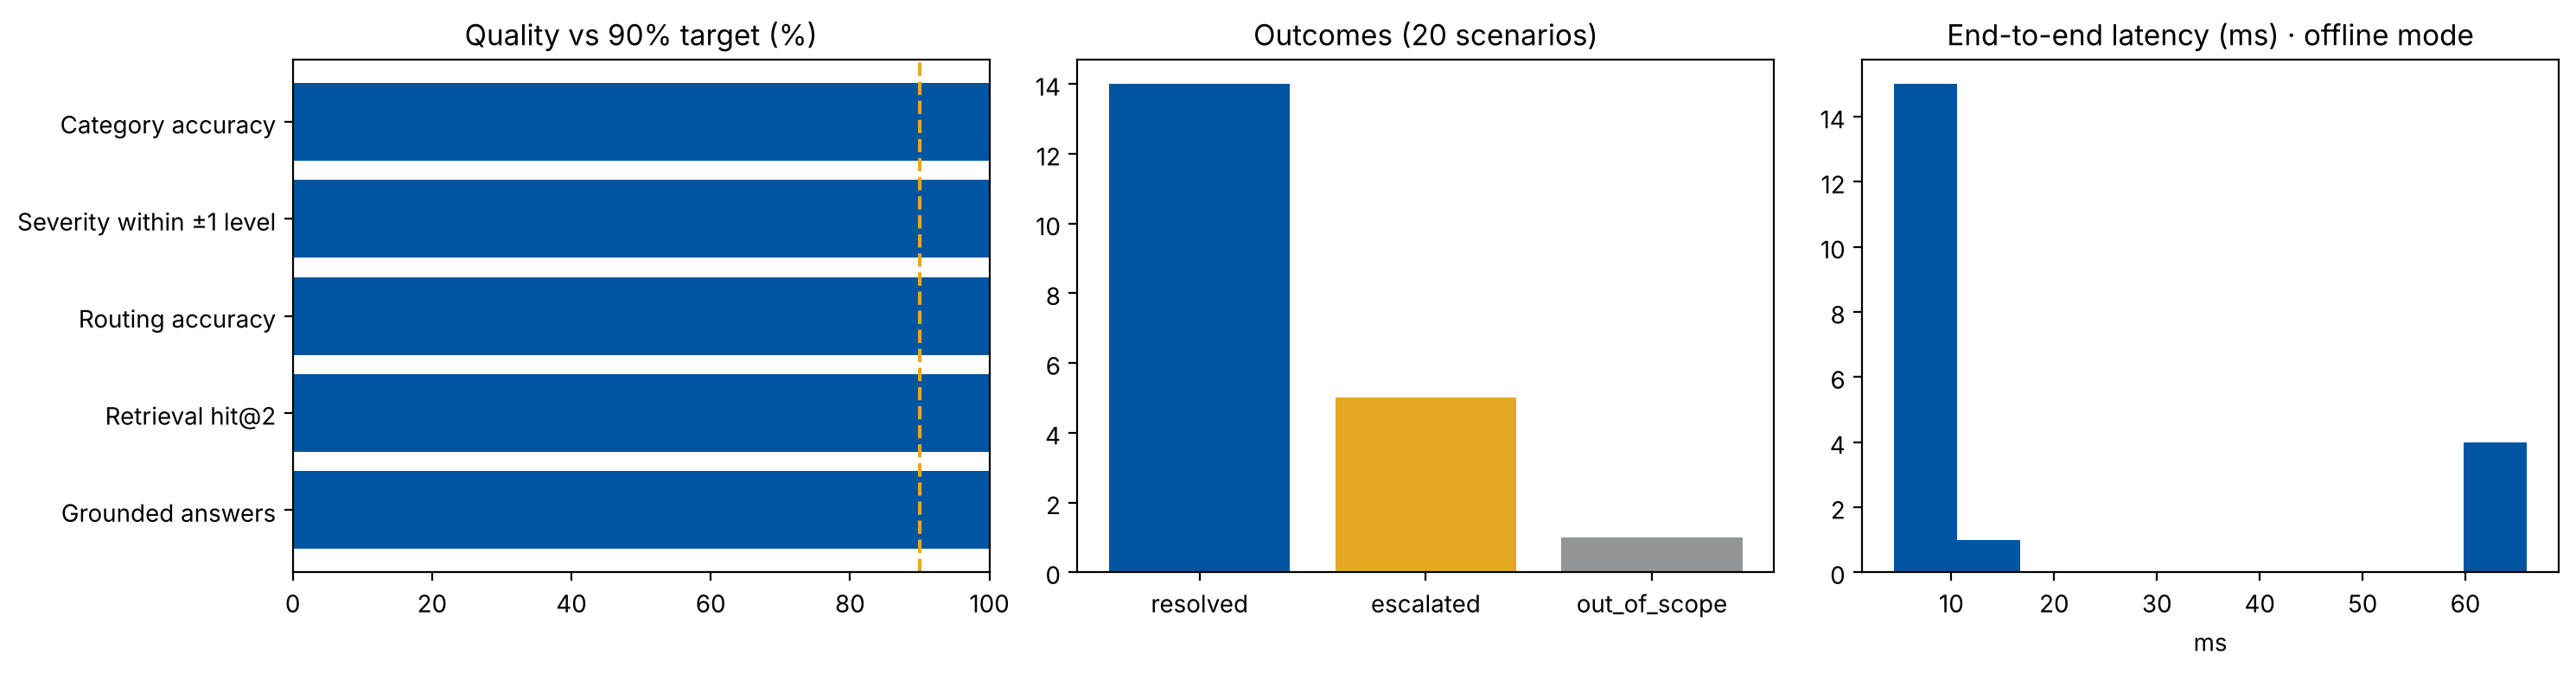

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
acc = {k: METRICS[k] for k in ["Category accuracy","Severity within ±1 level","Routing accuracy","Retrieval hit@2","Grounded answers"]}
axes[0].barh(list(acc)[::-1], [v*100 for v in list(acc.values())[::-1]], color="#0055A2")
axes[0].axvline(90, ls="--", c="#E5A823"); axes[0].set_xlim(0, 100); axes[0].set_title("Quality vs 90% target (%)")
out = results.status.value_counts()
axes[1].bar(out.index, out.values, color=["#0055A2","#E5A823","#939597"][:len(out)]); axes[1].set_title("Outcomes (20 scenarios)")
axes[2].hist(results.latency_ms, bins=10, color="#0055A2"); axes[2].set_title(f"End-to-end latency (ms) · {RUN_MODE} mode"); axes[2].set_xlabel("ms")
plt.tight_layout(); plt.savefig(os.path.join(WORKDIR, "validation_dashboard.png"), dpi=150); plt.show()

### Comparison with the sample notebook
| Metric | Sample notebook (4 demos, GPT-4o-mini) | SpartanAssist |
|---|---|---|
| Auto-resolved | 0 / 4 (0%) | see table above |
| Escalated | 4 / 4 (100%) | only when a policy rule fires |
| Avg latency | 16.5 s (double retrieval + 2 LLM calls) | one retrieval, ≤ 2 LLM calls, escalation LLM only when escalating |
| Accuracy scored vs labels | ✗ (self-reported confidence) | ✓ 20 labeled scenarios |
| Off-topic retrieval guard | ✗ (always top-2) | ✓ similarity threshold + citation check |

## 🔗 14 · MCP in action — the notebook as an MCP client
We start `helpdesk_mcp_server.py` as a subprocess, do the MCP handshake, **discover** its tools (no hard-coded endpoints), and call them. VS Code Copilot runs this same flow when it reads `.vscode/mcp.json`.

In [ ]:
import asyncio, sys
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client

async def mcp_demo():
    params = StdioServerParameters(command=sys.executable, args=["helpdesk_mcp_server.py"],
                                   env={**os.environ, "TICKET_DB": TICKET_DB})
    async with stdio_client(params) as (read, write):
        async with ClientSession(read, write) as session:
            info = await session.initialize()
            print(f"🤝 Connected to MCP server '{info.serverInfo.name}' (protocol {info.protocolVersion})")
            tools = (await session.list_tools()).tools
            print(f"🧰 Discovered {len(tools)} tools:")
            for t in tools: print(f"   • {t.name:<24} {t.description.splitlines()[0]}")
            r = await session.call_tool("list_tickets", {"status": "escalated", "limit": 5})
            print("\n📋 list_tickets(status='escalated') →")
            for c in r.content: print("  ", c.text[:220])
            r = await session.call_tool("create_ticket", {"user": "staff_demo", "category": "network",
                                        "priority": "P3", "summary": "Created from MCP client demo"})
            print("\n🎫 create_ticket →", r.content[0].text)

try:
    await mcp_demo()                      # Jupyter / Colab already run an event loop
except RuntimeError:
    asyncio.run(mcp_demo())

🤝 Connected to MCP server 'spartanassist-helpdesk' (protocol 2025-11-25)
🧰 Discovered 7 tools:
   • create_ticket            Create an IT support ticket. priority is P1-P4.
   • update_ticket            Change a ticket's status (open, resolved, escalated, closed).
   • list_tickets             List recent tickets, optionally filtered by status (open/resolved/escalated) and priority (P1-P4).
   • send_password_reset      Send a password reset link to the user's recovery email.
   • unlock_account           Unlock a locked account (does not work for disabled accounts).
   • run_network_diagnostics  Run DHCP/DNS/gateway/access-point checks for a user's location.
   • check_service_status     Get current status of campus IT services.

📋 list_tickets(status='escalated') →
   {
  "id": "INC-261112-38F6C",
  "created": "2026-11-12T11:29:17",
  "category": "hardware",
  "priority": "P4",
  "status": "escalated",
  "team": "desktop_support",
  "summary": "my laptop screen is cracked after I dro

**MCP vs. a traditional API integration**

| | Traditional REST integration | MCP |
|---|---|---|
| Discovery | Read the docs, hard-code each endpoint | `list_tools()` returns names, descriptions and JSON schemas at runtime |
| New client (VS Code, Claude, a Gemini agent) | Write a new connector per client | Any MCP client works with no code changes |
| Swapping back ends (simulated → Jira) | Change every caller | Change the server, and clients don't notice |
| Auth & permissions | Custom per API | OAuth at the server; remote servers like GitHub and Atlassian act with the user's own permissions |

## 💬 15 · Optional chat UI (Gradio)
This implements the chat wireframe from the UX design: the answer, an action chip, the ticket number and a "Talk to a person" escape hatch. Set `LAUNCH_UI = True` in Colab to get a shareable link for the live demo.

In [ ]:
LAUNCH_UI = False
if LAUNCH_UI:
    %pip install -q gradio
    import gradio as gr
    def chat(msg, history):
        o = ask(msg, "demo_user", verbose=False)
        badge = {"resolved": "🟢 Resolved", "escalated": "🟠 Sent to a person", "out_of_scope": "⚪ Out of scope"}[o["status"]]
        return f"{o['final_response']}\n\n_{badge} · {o['category']} · {o['severity']} · {o['latency_ms']/1000:.1f}s_"
    gr.ChatInterface(chat, title="SpartanAssist — Campus IT Help",
                     examples=["My wifi keeps dropping", "I'm locked out of my account", "How do I print in color?",
                               "I clicked a phishing link"]).launch(share=True)
else:
    print("UI disabled — set LAUNCH_UI = True to launch the Gradio chat demo.")

UI disabled — set LAUNCH_UI = True to launch the Gradio chat demo.


## 📝 16 · Lessons learned & next steps
- **Rules + LLM beats LLM alone for routing.** The rules make escalation decisions explainable and testable; the LLM handles language understanding.
- **Thresholds matter more than k.** Dropping weak matches fixed the sample's "VPN guide shows up for Wi-Fi" problem and gave us an honest "I don't know" path.
- **Redact first.** Running privacy before every other node means we never have to trust downstream components with PII.
- **MCP made the staff side free.** The same server that the agents use is usable from VS Code Copilot with no extra code.
- **Next:** connect `create_ticket` to Jira Service Management via the Atlassian Rovo MCP server; replace the simulated IdP with Okta; add feedback thumbs into the ticket table to measure real CSAT; evaluate with RAGAS on a larger test set.